<a href="https://colab.research.google.com/github/Tiyinolalekan/Deep_Learning_Image_Classifier/blob/main/Second_Stage_Grocery_Classifier_V1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ***SECOND STAGE : CLOTHING SPECIALIST***

This notebook builds, trains, validates and tests a CNN model (VGG-style, trained from scratch) that will classify clothing apparels into their respective subcategories.

Relevant library imports.

In [ ]:
#Imports
import torch #Main PyTorch library
import torch.nn as nn # Neural network compnents
import torch.optim as optim #Optimisers for training
import torchvision #Computer-vision datasets/tools
from torchvision import datasets, models #Importing datasets and models
import torchvision.transforms as transforms #Preparing images
import matplotlib.pyplot as plt #to visualise images
from torch.utils.data import DataLoader
from torchvision.utils import make_grid
import time
import copy
import numpy as np
import pandas as pd

#CHECKING IMPORTS AND RUNTIME
print(torch.__version__)
print(torch.cuda.is_available()) #Checking if a GPU is available

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu') ##Resulting to use CPU if GPU isnt available. GPU is preferred cause it performs multiple AI mathematical calculations faster
print(device)

2.14.1+cpu
False
cpu


Mounting google drive folder to retrive stored dataset

In [ ]:
#Mounting google drive into content folder
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Copying dataset from drive folder into a more accessible folder

In [ ]:
!mkdir -p /content/data
!cp -r /content/drive/MyDrive/neura_data/groceries_sorted /content/data/

Checking data copied over correctly

In [ ]:
!find /content/data/groceries_sorted/train -type f | wc -l

4721


Constructing paths to dataset folders

In [ ]:
from pathlib import Path

print(Path("/content/data/groceries_sorted").exists()) #checking if file exists
root_path = "/content/data/groceries_sorted"
train_dir = root_path + "/train"
val_dir = root_path + "/val"
test_dir = root_path + "/test"
print(Path(train_dir).exists())
print(Path(val_dir).exists())
print(Path(test_dir).exists())

True
True
True
True


**Normalisation using empirically determined mean and standard deviation values.**

In [ ]:
mean = [0.485, 0.456, 0.406] #Imperatively found as studies show
std = [0.229, 0.224, 0.225]

**De-normalise the images**

In [ ]:
inv_normalize = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)

**Transformations**: Transforming the data using the torchvision library.

In [ ]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),  #Resezies to 224x224 pixels to match the original VGG-16 network
    transforms.RandomHorizontalFlip(), #Default 0.5 i.e., 50% chance of image being flipped
    transforms.ToTensor(),  #Converting it to tensors
    transforms.Normalize(mean, std) #Normalising the images (will need to denormalise to view images properly)
])

#Transform for validation/test data: same as above but with NO random flip so results are repeatable
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

#Copy of dataset for examples/checks below
train_dataset = datasets.ImageFolder(
    train_dir,
    transform=transforms.Compose([  ##Adding additional dat augmentation to the train dataset to help with model overfitting
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])
)

Peeking at class structure

In [ ]:
print(train_dataset.classes)
print(len(train_dataset.classes))

['BEANS', 'CAKE', 'CANDY', 'CEREAL', 'CHIPS', 'CHOCOLATE', 'COFFEE', 'FISH', 'FLOUR', 'FRUIT', 'HONEY', 'JAM', 'JUICE', 'MILK', 'NUTS', 'OIL', 'PASTA', 'RICE', 'SODA', 'SPICES', 'SUGAR', 'SWEET CORN', 'TEA', 'TOMATO_SAUCE', 'VEGETABLE', 'VINEGAR', 'WATER']
27


Naming Classes

In [ ]:
classes = train_dataset.classes

#Peeking
image, label = train_dataset[0]
print(image.shape) #First element represents the number of color channels,a nd remaning two is the height and width based on the number of pixels
print(label)
print(classes[label])

torch.Size([3, 224, 224])
0
BEANS


Displaying a test image using matplotlib to ensure the images load in correctly

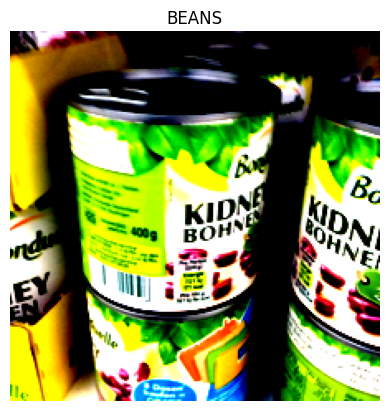

In [ ]:
#Displaying image using matplotlib

plt.imshow(image.permute(1,2,0)) #rearranged dimensions to be height, width and channels where, 0,1,2 are indicies from the image.shape array e.g., [3,32,32] becomes (32,32,3)
plt.title(classes[label])
plt.axis("off")
plt.show()

# ***ALEXNET PRETRAINED MODEL***

In [ ]:
AlexNet = models.alexnet(pretrained=True) #Using the pretrained AlexNet model
AlexNet

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(6, 6))
  (classifier): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=9216, out_features=4096, bias=True)
 

Freezing features in the model

In [ ]:
for param in AlexNet.parameters():
  param.requires_grad = False #Freezing the features in the model

In [ ]:
torch.manual_seed(42) #Seeding the dataset to get the same results all the time
AlexNet.classifier = nn.Sequential( nn.Linear(9216, 512),
                                    nn.ReLU(),
                                    nn.Dropout(0.5),
                                    nn.Linear(512, len(classes))
                                   )
AlexNet

AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(6, 6))
  (classifier): Sequential(
    (0): Linear(in_features=9216, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.5, i

In [ ]:
##Counting parameters
params = [p.numel() for p in AlexNet.parameters() if p.requires_grad]
for item in params:
  print(f'{item:>8}')

 4718592
     512
   13824
      27


# ***CREATING THE MODEL***

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu") #Using the CPU to train if no GPU's are detected

class CNN(nn.Module): #Inheritnce class
  def __init__(self):
    super().__init__()
    #BLOCK ONE
    self.block1 = nn.Sequential(
          #First Convolutional layer
                  nn.Conv2d(
                      in_channels=3,
                      out_channels=64,
                      kernel_size=3,
                      padding=1
                      ),

                  nn.BatchNorm2d(64),
                  nn.ReLU(inplace=True),
              #Second Convolution
              #Do two times the convolution in the FIRST block according to VGG model to boost accuracy
                nn.Conv2d(
                        in_channels=64,
                        out_channels=64,
                        kernel_size=3,
                        padding=1
                      ),

                  nn.BatchNorm2d(64),
                  nn.ReLU(inplace=True),
                  nn.MaxPool2d(2) # where kernel_size=2 stride=2
          )

      #BLOCK TWO
    self.block2 = nn.Sequential(
          #Third Convolutional layer
                  nn.Conv2d(
                      in_channels=64,
                      out_channels=128,
                      kernel_size=3,
                      padding=1
                      ),

                  nn.BatchNorm2d(128),
                  nn.ReLU(inplace=True),
              #Fourth Convolution
              #Do two times the convolution in the Second block according to VGG model to boost accuracy
                nn.Conv2d(
                        in_channels=128,
                        out_channels=128,
                        kernel_size=3,
                        padding=1
                      ),

                  nn.BatchNorm2d(128),
                  nn.ReLU(inplace=True),
                  nn.MaxPool2d(2) # where kernel_size=2 stride=2
          )

      #BLOCK THREE
    self.block3 = nn.Sequential(
          #Fifth Convolutional layer
                  nn.Conv2d(
                      in_channels=128,
                      out_channels=256,
                      kernel_size=3,
                      padding=1
                      ),

                  nn.BatchNorm2d(256),
                  nn.ReLU(inplace=True),
              #sixth Convolution
                nn.Conv2d(
                        in_channels=256,
                        out_channels=256,
                        kernel_size=3,
                        padding=1
                      ),

                  nn.BatchNorm2d(256),
                  nn.ReLU(inplace=True),

          #seventh Convolution
              #Do three times the convolution in the Third block according to VGG model to boost accuracy
                nn.Conv2d(
                        in_channels=256,
                        out_channels=256,
                        kernel_size=3,
                        padding=1
                      ),

                  nn.BatchNorm2d(256),
                  nn.ReLU(inplace=True),
                  nn.MaxPool2d(2) # where kernel_size=2 stride=2
          )


      #BLOCK FOUR
    self.block4 = nn.Sequential(
          #Eight Convolutional layer
                  nn.Conv2d(
                      in_channels=256,
                      out_channels=512,
                      kernel_size=3,
                      padding=1
                      ),

                  nn.BatchNorm2d(512),
                  nn.ReLU(inplace=True),
              #Ninth Convolution
                nn.Conv2d(
                        in_channels=512,
                        out_channels=512,
                        kernel_size=3,
                        padding=1
                      ),

                  nn.BatchNorm2d(512),
                  nn.ReLU(inplace=True),
          #Tenth Convolution
        #Do three times the convolution in the Third block according to VGG model to boost accuracy
                nn.Conv2d(
                        in_channels=512,
                        out_channels=512,
                        kernel_size=3,
                        padding=1
                      ),

                  nn.BatchNorm2d(512),
                  nn.ReLU(inplace=True),
                  nn.MaxPool2d(2) # where kernel_size=2 stride=2
          )
      #BLOCK 5
    self.block5 = nn.Sequential(
          #Eleventh Convolutional layer
                  nn.Conv2d(
                      in_channels=512,
                      out_channels=512,
                      kernel_size=3,
                      padding=1
                      ),

                  nn.BatchNorm2d(512),
                  nn.ReLU(inplace=True),
              #Twelfth Convolution
                nn.Conv2d(
                        in_channels=512,
                        out_channels=512,
                        kernel_size=3,
                        padding=1
                      ),

                  nn.BatchNorm2d(512),
                  nn.ReLU(inplace=True),
          #Thirteenth Convolution
        #Do three times the convolution in the Third block according to VGG model to boost accuracy
                nn.Conv2d(
                        in_channels=512,
                        out_channels=512,
                        kernel_size=3,
                        padding=1
                      ),

                  nn.BatchNorm2d(512),
                  nn.ReLU(inplace=True),
                  nn.MaxPool2d(2) # where kernel_size=2 stride=2
          )

    #Global average pooling collapses each 512 x 7 x 7 feature map into a single value (512 numbers in total).
    #This replaces flattening to 25088 and removes the huge 25088 -> 4096 layer that made training unstable from scratch
    self.pool = nn.AdaptiveAvgPool2d(1)

    self.dropout = nn.Dropout(0.5) #Randomly deactivating neurons by zeroing out a fraction of neurons in a layer to prevent overfitting
    self.relu = nn.ReLU(inplace=True)

    #Fully Connected layer one (smaller head)
    self.fc1 = nn.Linear(512, 256)

    #Fully Connected layer two: final prediction over the 11 classes in the dataset
    self.fc2 = nn.Linear(256, 11)

  def forward(self, x):
      #Using the blocks assembled and applying them sequentially to the variable
      x = self.block1(x)
      x = self.block2(x)
      x = self.block3(x)
      x = self.block4(x)
      x = self.block5(x)

      x = self.pool(x)
      x = torch.flatten(x, 1)  #Flattening to [batch, 512]
      x = self.fc1(x)
      x = self.relu(x)
      x = self.dropout(x)
      x = self.fc2(x)

      return x


In [ ]:
 #Instantiate and move to device
model = CNN()
model = model.to(device) #Moving to GPU if avilable

Checking if Cuda is being used

In [ ]:
print(device)                           # should say cuda
print(next(model.parameters()).device)  # should say cuda:0

cpu


NameError: name 'model' is not defined

Loading the data into the pretrained model

In [ ]:
#Getting test data from their folders
train_dataset = datasets.ImageFolder(
    train_dir,
    transform=transform
)

val_dataset = datasets.ImageFolder(
    val_dir,
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=eval_transform
)
#torch.manual_seed(42) #Seeding the dataset to get the same results all the time
#Loading the data in batches of 64 then shuffling it to enable randomisation and efficient learning
train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True
)

test_loader = DataLoader(
    test_dataset, batch_size=64, shuffle=False
)

val_loader = DataLoader(
    val_dataset, batch_size=64, shuffle=False
)

#Calculating sample weights to handle dataset imbalance
counts = torch.bincount(torch.tensor(train_dataset.targets))
sample_weights = len(train_dataset) / (len(counts) * counts.float())
torch.manual_seed(42) #Seeding the dataset to get the same results all the time
#Loss Function
criterion = nn.CrossEntropyLoss(weight=sample_weights.to(device)) #Produce sample losses instaed of combining all losses in order to initiate sample weights to handle dataset imbalance.

#Optimizer
optimizer = optim.Adam( #the algorithm we're using to update the weights
    AlexNet.classifier.parameters(),#all the weights and biases the model can learn
    lr=0.0001, #lowered from 0.001: learning rate controls how big each weight update is, and 0.001 made training collapse
    weight_decay=1e-4
)

#Scheduler: halves the learning rate when the training loss stops improving
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=1)

Peeking into the dataset

In [ ]:
print(train_dataset)
print(test_dataset)
print(val_dataset)

print()
print(len(train_dataset))
print(len(test_dataset))
print(len(val_dataset))

Dataset ImageFolder
    Number of datapoints: 4721
    Root location: /content/data/groceries_sorted/train
    StandardTransform
Transform: Compose(
               Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.5)
               ToTensor()
               Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
           )
Dataset ImageFolder
    Number of datapoints: 605
    Root location: /content/data/groceries_sorted/test
    StandardTransform
Transform: Compose(
               Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
               ToTensor()
               Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
           )
Dataset ImageFolder
    Number of datapoints: 592
    Root location: /content/data/groceries_sorted/val
    StandardTransform
Transform: Compose(
               Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=T

Displaying Image Batch

Lables:  [ 6  7 10  5  8 10  7  7 10  4  7  9 10  6 10  1  7 10 10  7 10  6  0  6
  6  8 10  7 10  7  7 10 10  5  5  0 10 10  7  5 10  5  7 10  7  5 10 10
  6 10  7  9 10  6  3 10  8 10 10  7  4  6 10 10]
Classes:  shirt shoes t-shirt pants shorts t-shirt shoes shoes t-shirt outwear shoes skirt t-shirt shirt t-shirt hat shoes t-shirt t-shirt shoes t-shirt shirt dress shirt shirt shorts t-shirt shoes t-shirt shoes shoes t-shirt t-shirt pants pants dress t-shirt t-shirt shoes pants t-shirt pants shoes t-shirt shoes pants t-shirt t-shirt shirt t-shirt shoes skirt t-shirt shirt longsleeve t-shirt shorts t-shirt t-shirt shoes outwear shirt t-shirt t-shirt


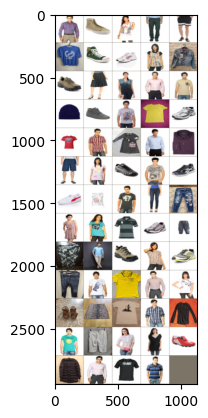

In [ ]:
for images, labels in train_loader:
  break #only labels

print('Lables: ', labels.numpy())
print("Classes: ", *np.array([classes[i] for i in labels]))

im = make_grid(images, nrow=5)
im_inv = inv_normalize(im) #De normalising images
plt.imshow(np.transpose(im_inv.numpy(), (1,2,0)))
plt.show()

Leakage Check

In [ ]:
import hashlib, os

def file_hashes(folder):
    out = set()
    for r, _, fs in os.walk(folder):
        for f in fs:
            with open(os.path.join(r, f), "rb") as fh:
                out.add(hashlib.md5(fh.read()).hexdigest())
    return out

tr, va, te = file_hashes(train_dir), file_hashes(val_dir), file_hashes(test_dir)
print("train/test overlap:", len(tr & te))
print("train/val overlap: ", len(tr & va))
print("val/test overlap:  ", len(va & te))

print()




train/test overlap: 0
train/val overlap:  0
val/test overlap:   0



***Model Evaluation***

In [ ]:
def evaluation(model, loader):
  AlexNet.eval()  #Entering evaluation mode
  correct = 0  #number of correct guesses
  total = 0 #total number of predictions

  with torch.no_grad(): #no gradients needed cause model is learning not measuring

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = AlexNet(images) #logits for each test image So outputs has shape [64, 11]: 64 rows (one per image) and 11 columns (one score per class).
        _, predicted = torch.max(outputs,1) #Returns the class with the highest logit
        total += labels.size(0) #Getting the total number of images in the batch
        correct += (predicted == labels).sum().item()  #how many were right. .item() pulls that single value out of the tensor as a plain Python number


  accuracy = 100 * correct / total
  print(f"Accuracy: {accuracy:.2f}%")
  return accuracy


def test_evaluation(model, loader):
  model.eval()  #Entering evaluation mode
  correct = 0
  total = 0
  running_loss = 0.0  #adding up the loss

  with torch.no_grad():
    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)  #loss for this batch
        running_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

  accuracy = 100 * correct / total
  avg_loss = running_loss / len(loader)
  print(f"Accuracy: {accuracy:.2f}%, Loss: {avg_loss:.4f}")
  return accuracy, avg_loss




# ***MAIN TRAINING LOOP***

In [ ]:
num_epochs = 10 #the model goes through the entire 50,000-image training dataset 10 times.
train_losses = []
val_losses = []
best_val_loss = float('inf')
patience = 3  #how many epochs to wait for an improvement
epochs_without_improvement = 0


for epoch in range(num_epochs) :

  AlexNet.train() #Training the model
  running_loss = 0.0

  for images, labels in train_loader: #Iterating through the 64/9000+ -image training dataset

    images = images.to(device) #Inputs
    labels = labels.to(device) #Outputs


    optimizer.zero_grad() #clears the gradients from the previous batch
    outputs = AlexNet(images) #forward pass; the CNN makes predictions.

    #outputs are raw logits; CrossEntropyLoss handles softmax internally
    loss = criterion(outputs, labels) #* sample_weights).mean() # calculates how wrong those predictions are.
    loss.backward() #backpropagation; calculates the gradient for EVERY learnable weight.
    torch.nn.utils.clip_grad_norm_(AlexNet.parameters(), max_norm=1.0) #gradient clipping: caps the update size so one bad batch can't derail training

    optimizer.step() #uses those gradients to update the weights.

    running_loss += loss.item()

  epoch_loss = running_loss/len(train_loader)
  train_losses.append(epoch_loss)

  #Validation pass
  val_acc, val_loss = test_evaluation(AlexNet, val_loader)
  val_losses.append(val_loss)

  scheduler.step(val_loss)  #now based on val loss, not train loss

  print(f"Epoch {epoch+1}/{num_epochs}, Train Loss: {epoch_loss:.4f}, Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%")

  #Early stopping + saving the best model
  if val_loss < best_val_loss:
    best_val_loss = val_loss
    epochs_without_improvement = 0
    torch.save(AlexNet.state_dict(), "best_alexnet.pth")
  else:
    epochs_without_improvement += 1
    if epochs_without_improvement >= patience:
      print("Early stopping")
      break

  #Load the best version before testing
  AlexNet.load_state_dict(torch.load("best_alexnet.pth"))

Accuracy: 63.18%, Loss: 1.2266
Epoch 1/10, Train Loss: 1.4342, Val Loss: 1.2266, Val Acc: 63.18%
Accuracy: 66.22%, Loss: 1.1083
Epoch 2/10, Train Loss: 1.0532, Val Loss: 1.1083, Val Acc: 66.22%
Accuracy: 66.89%, Loss: 1.0354
Epoch 3/10, Train Loss: 0.8189, Val Loss: 1.0354, Val Acc: 66.89%
Accuracy: 71.62%, Loss: 0.9450
Epoch 4/10, Train Loss: 0.6423, Val Loss: 0.9450, Val Acc: 71.62%
Accuracy: 71.62%, Loss: 0.9201
Epoch 5/10, Train Loss: 0.5059, Val Loss: 0.9201, Val Acc: 71.62%
Accuracy: 72.30%, Loss: 0.9036
Epoch 6/10, Train Loss: 0.4274, Val Loss: 0.9036, Val Acc: 72.30%
Accuracy: 72.47%, Loss: 0.8595
Epoch 7/10, Train Loss: 0.3441, Val Loss: 0.8595, Val Acc: 72.47%
Accuracy: 71.62%, Loss: 0.8616
Epoch 8/10, Train Loss: 0.2846, Val Loss: 0.8616, Val Acc: 71.62%
Accuracy: 71.45%, Loss: 0.8869
Epoch 9/10, Train Loss: 0.2855, Val Loss: 0.8869, Val Acc: 71.45%
Accuracy: 72.97%, Loss: 0.8512
Epoch 10/10, Train Loss: 0.2534, Val Loss: 0.8512, Val Acc: 72.97%


In [52]:
test_eval = evaluation(AlexNet, test_loader)


Accuracy: 70.41%


In [54]:
train_eval = evaluation(AlexNet, train_loader)

Accuracy: 98.33%


In [53]:
val_eval = evaluation(AlexNet, val_loader)

Accuracy: 72.97%


***BASELINE UPON FIRST EVER RUN***:
_____________________________


*   Final Training Loss: 0.1313
*   Test Accurracy: 69.26%
*   Validation Accuracy: 74.16%
*   Training Accuracy: 98.58%
*   Gap (between test and train):approximately 29.32 points.



***Loss Curve***

In [ ]:
import matplotlib.pyplot as plt

plt.plot(train_losses, label='Train Loss')
plt.xlabel('Epoch')
plt.ylabel('Training Loss')
plt.title('Training Loss Curve')
plt.ticklabel_format(style='plain', axis='y')
plt.legend()
plt.show()

# ***DEBUGGING CELLS***

Checking location and size of the dataset and its stored images

In [ ]:
#Checking location and size of the dataset and its stored images
import os
from PIL import Image

path = train_dir          # paste your real path
print(path)                           # does it start with /content/drive ?

for root, _, files in os.walk(path):
    if files:
        img = Image.open(os.path.join(root, files[0]))
        print(img.size, round(os.path.getsize(os.path.join(root, files[0])) / 1e6, 2), "MB")
        break

/content/data/router_dataset/train
(2621, 2736) 0.54 MB


Checking how big the images are

In [ ]:
import os, random
from PIL import Image

files = [os.path.join(r, f) for r, _, fs in os.walk(train_dir) for f in fs]
print(len(files), "files")

sample = random.sample(files, min(200, len(files)))
widths = sorted(Image.open(f).size[0] for f in sample)
print("width min / median / max:", widths[0], widths[len(widths)//2], widths[-1])

9006 files
width min / median / max: 100 384 2736


Getting Loading time of the model

In [ ]:

#Getting loading time of the model
import time

print(device, next(AlexNet.parameters()))
print(len(train_loader), "batches per epoch")

AlexNet.train()
t_load = t_comp = 0
end = time.time()
for i, (images, labels) in enumerate(train_loader):
    t_load += time.time() - end
    t0 = time.time()
    images, labels = images.to(device), labels.to(device)
    optimizer.zero_grad()
    loss = criterion(AlexNet(images), labels)
    loss.backward()
    optimizer.step()
    if device.type == "cuda":
        torch.cuda.synchronize()
    t_comp += time.time() - t0
    end = time.time()
    if i == 19:
        break

print(f"loading: {t_load:.1f}s, compute: {t_comp:.1f}s for 20 batches")
print("estimated epoch (min):", round((t_load + t_comp) / 20 * len(train_loader) / 60, 1))

cpu Parameter containing:
tensor([[[[ 1.1864e-01,  9.4069e-02,  9.5435e-02,  ...,  5.5822e-02,
            2.1575e-02,  4.9963e-02],
          [ 7.4882e-02,  3.8940e-02,  5.2979e-02,  ...,  2.5709e-02,
           -1.1299e-02,  4.1590e-03],
          [ 7.5425e-02,  3.8779e-02,  5.4930e-02,  ...,  4.3596e-02,
            1.0225e-02,  1.3251e-02],
          ...,
          [ 9.3155e-02,  1.0374e-01,  6.7547e-02,  ..., -2.0277e-01,
           -1.2839e-01, -1.1220e-01],
          [ 4.3544e-02,  6.4916e-02,  3.6164e-02,  ..., -2.0248e-01,
           -1.1376e-01, -1.0719e-01],
          [ 4.7369e-02,  6.2543e-02,  2.4758e-02,  ..., -1.1844e-01,
           -9.5567e-02, -8.3890e-02]],

         [[-7.2634e-02, -5.7996e-02, -8.0661e-02,  ..., -6.0304e-04,
           -2.5309e-02,  2.5471e-02],
          [-6.9042e-02, -6.7562e-02, -7.6367e-02,  ..., -3.9616e-03,
           -3.0402e-02,  1.0477e-02],
          [-9.9517e-02, -8.5592e-02, -1.0521e-01,  ..., -2.6587e-02,
           -2.2777e-02,  6.6451e

Removing Duplicates

In [ ]:
import hashlib, os

def get_file_hashes(path):
    with open(path, "rb") as fh:
        return hashlib.md5(fh.read()).hexdigest()  # calculating unique hash for passed file path

def get_hashes(folder):
    hashes = set()
    for r, _, fs in os.walk(folder):
        for f in fs:
            hashes.add(get_file_hashes(os.path.join(r, f)))  # adding all unique file hashes in the folder to a set
    return hashes


def remove_duplicates(train_dir, test_dir, val_dir):
    # Getting test dataset hashes
    test_hashes = get_hashes(test_dir)
        # Validation must not overlap with test or train
    val_hashes = get_hashes(val_dir)
    val_deleted = 0


    train_deleted_tests = 0  # Number of duplicate test data deleted
    train_deleted_val = 0  # Number of duplicate val data deleted

    # Iterating through the train dataset to check for duplicates
    for root, _, files in os.walk(train_dir):
        for file in files:
            path = os.path.join(root, file)
            if get_file_hashes(path) in test_hashes:  # comparing test data first to training data
                os.remove(path)  # deleting duplicate if fuond
                train_deleted_tests += 1  # incrementing deleted values

    for root, _, files in os.walk(train_dir):
        for file in files:
            path_v = os.path.join(root, file)
            if get_file_hashes(path_v) in val_hashes:
                os.remove(path_v)
                train_deleted_val += 1

    print("Deleted", train_deleted_tests, "test files")
    print("Deleted", train_deleted_val, "val files")

remove_duplicates(train_dir, test_dir, val_dir) # Recalculate hashes after cleaning training
train_hashes = get_hashes(train_dir)











Deleted 146 test files
Deleted 118 val files


Removing duplicates in test and val datasets

In [ ]:
def remove_test_val_duplicates(test_dir, val_dir):
    test_hashes = get_hashes(test_dir)
    val_hashes = get_hashes(val_dir)
    test_deleted = 0
    val_deleted = 0
    for root, _, files in os.walk(test_dir):
        for file in files:
            path = os.path.join(root, file)
            if get_file_hashes(path) in val_hashes:
                os.remove(path)
                test_deleted += 1
    for root, _, files in os.walk(val_dir):
        for file in files:
            path = os.path.join(root, file)
            if get_file_hashes(path) in test_hashes:
                os.remove(path)
                val_deleted += 1
    print("Deleted", test_deleted, "test files")
    print("Deleted", val_deleted, "val files")

remove_test_val_duplicates(test_dir, val_dir)

Deleted 20 test files
Deleted 20 val files
